# Week 6 - Task C: the figure the board will actually see

**Reader:** the National Grid Authority board, splitting the reliability budget across 24 districts.
**Question:** where is supply least reliable? Not where are there most interruptions, but where is service worst for the people served.

Reads `clean/district_grid_clean.csv` (run Task A first) and `data/regions.geojson`. The half-page note is `partC_note.md`.

All data is synthetic course data for CDB601220 (Week 6).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    HERE = Path(__file__).resolve().parent
    IN_NOTEBOOK = False
except NameError:
    HERE = Path.cwd() / "submission"
    IN_NOTEBOOK = True


def find_root(start):
    for cand in (start.parent, start, start.parent / "assignments", start / "assignments"):
        if (cand / "data" / "district_grid.csv").exists() and (cand / "geolib.py").exists():
            return cand
    raise SystemExit("Can't find data/ and the toolkits. Put this folder next to them (see README).")


ROOT = find_root(HERE)
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import geolib as gl
import vizlib as vz
from vizlib import PALETTE, save_fig, style_defaults

CLEAN = HERE / "clean"
if not (CLEAN / "district_grid_clean.csv").exists():
    raise SystemExit("clean/ is empty: run partA_process.py first")
CHARTS = ROOT / "charts"
if IN_NOTEBOOK:
    CHARTS.mkdir(exist_ok=True)
style_defaults()
BLUE, ORANGE = PALETTE["series"][0], PALETTE["highlight"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]

## 1 · Join, normalize, and the numbers behind the figure

**Denominator: billed households.** Interruptions are counted on the feeders that serve billed connections, so "interruptions per 1,000 households" is the closest thing in the file to "how often does a connected home lose supply". Population would also count people who aren't connected (electrification is 67-90%).

In [2]:
reg = pd.read_csv(CLEAN / "district_grid_clean.csv")
feats = gl.read_geojson(ROOT / "data" / "regions.geojson")
geo = {f["code"] for f in feats}
print(f"join on code: {len(geo & set(reg.code))} matched | rows with no polygon {len(set(reg.code) - geo)} | polygons with no row {len(geo - set(reg.code))}")
assert len(reg) == 24 and geo == set(reg.code)

reg["rate"] = reg.outages / reg.households * 1000
pooled = reg.outages.sum() / reg.households.sum() * 1000
r_count = reg.outages.corr(reg.households)
r_rate = reg.rate.corr(reg.households)
r_income = reg.rate.corr(reg.income_pc_usd)
top_count = reg.nlargest(3, "outages").code.tolist()
top_rate = reg.nlargest(3, "rate").code.tolist()
both = sorted(set(top_count) & set(top_rate))
reg["rank_rate"] = reg.rate.rank(ascending=False).astype(int)
reg["rank_count"] = reg.outages.rank(ascending=False).astype(int)
area = {f["code"]: gl.polygon_area_km2(f["ring"]) for f in feats}
reg["area_geo"] = reg.code.map(area)
big5 = reg.nlargest(5, "population")
land5, people5 = big5.area_geo.sum() / reg.area_geo.sum(), big5.population.sum() / reg.population.sum()

print(f"r(interruptions, households) = {r_count:+.3f} | r(rate per 1,000 households, households) = {r_rate:+.3f}")
print(f"top 3 by count {top_count} | by rate {top_rate} | on both: {both}")
print(f"national pooled rate {pooled:.1f} interruptions per 1,000 households ({reg.outages.sum():,} / {reg.households.sum():,})")
print(f"5 most populous {big5.code.tolist()}: {land5 * 100:.1f}% of the land, {people5 * 100:.1f}% of the people")
print(f"r(rate, income per head) = {r_income:+.3f}; incomes of the top 3 by rate: {reg.set_index('code').loc[top_rate, 'income_pc_usd'].tolist()}, median {reg.income_pc_usd.median():,.0f}")
assert round(r_count, 3) == 0.991 and round(r_rate, 3) == 0.175
assert top_count == ["D17", "D13", "D24"] and top_rate == ["D12", "D11", "D13"] and len(both) == 1
assert round(pooled, 1) == 43.7 and round(land5 * 100, 1) == 12.6 and round(people5 * 100, 1) == 59.9

cols = ["code", "district", "households", "outages", "rate", "rank_rate", "rank_count", "income_pc_usd"]
print(reg.sort_values("rate", ascending=False)[cols].round(1).to_string(index=False))

join on code: 24 matched | rows with no polygon 0 | polygons with no row 0
r(interruptions, households) = +0.991 | r(rate per 1,000 households, households) = +0.175
top 3 by count ['D17', 'D13', 'D24'] | by rate ['D12', 'D11', 'D13'] | on both: ['D13']
national pooled rate 43.7 interruptions per 1,000 households (388,879 / 8,908,512)
5 most populous ['D17', 'D09', 'D24', 'D13', 'D11']: 12.6% of the land, 59.9% of the people
r(rate, income per head) = -0.710; incomes of the top 3 by rate: [4500, 5950, 2600], median 6,450
code      district  households  outages  rate  rank_rate  rank_count  income_pc_usd
 D12       Lashkar      237190    12067  50.9          1           8           4500
 D11         Kotla      616114    31283  50.8          2           5           5950
 D13      Mehrabad     1110000    55879  50.3          3           2           2600
 D18   Rohtas West      225481    10997  48.8          4          13           4450
 D03        Chakwa      170859     8276  48.4         

**The one district on both lists is Mehrabad (D13).** It is on the count list because it is big (1.11 million households, second largest), but that is not why it is on the rate list: rate and size are almost unrelated (r = +0.18). It is on the rate list because it is poor. Mehrabad has the joint-lowest income in the federation ($2,600 a head, tied with Virkabad), and across the 24 districts the rate falls as income rises (r = -0.71). D17 and D24, the other two on the count list, are below the national rate.

## 2 · Is any district too small or too uncertain to publish?

Rule fixed before looking at the map: suppress a district if it has fewer than 20 interruptions or fewer than 10,000 households. Then the funnel (`geolib.funnel_limits`, Poisson, 95%) says which rates are distinguishable from the national one.

In [3]:
MIN_EVENTS, MIN_HH = 20, 10_000
suppressed = reg[(reg.outages < MIN_EVENTS) | (reg.households < MIN_HH)]
print(f"suppression rule: < {MIN_EVENTS} interruptions or < {MIN_HH:,} households -> {len(suppressed)} suppressed "
      f"(smallest: {reg.outages.min():,} interruptions, {reg.households.min():,} households)")
lam = pooled / 1000 * reg.households
reg["hi"] = (lam + 1.96 * np.sqrt(lam)) / reg.households * 1000
reg["lo"] = (lam - 1.96 * np.sqrt(lam)) / reg.households * 1000
above, below = reg[reg.rate > reg.hi], reg[reg.rate < reg.lo]
inside = reg[(reg.rate <= reg.hi) & (reg.rate >= reg.lo)]
fl = gl.funnel_limits(reg.households, pooled, per=1000)
print(f"95% band at the smallest district ({fl.population.iloc[0]:,.0f} households): {fl.lo.iloc[0]:.1f} - {fl.hi.iloc[0]:.1f}; "
      f"at the largest ({fl.population.iloc[-1]:,.0f}): {fl.lo.iloc[-1]:.1f} - {fl.hi.iloc[-1]:.1f}")
print(f"above the band: {len(above)} {above.sort_values('rate', ascending=False).code.tolist()} | inside: {len(inside)} {inside.code.tolist()} | below: {len(below)}")

suppression rule: < 20 interruptions or < 10,000 households -> 0 suppressed (smallest: 3,234 interruptions, 76,721 households)
95% band at the smallest district (76,721 households): 42.2 - 45.1; at the largest (1,566,571): 43.3 - 44.0
above the band: 8 ['D12', 'D11', 'D13', 'D18', 'D03', 'D21', 'D14', 'D22'] | inside: 2 ['D07', 'D10'] | below: 14


Nothing is suppressed: the smallest counts in the register are 3,234 interruptions (D16) and 76,721 households (D14), and even at 76,721 households the 95% band around the national rate is only 42.2-45.1. With counts this large almost every gap is real: 8 districts are above the national band, 14 below and only 2 inside it.

## 3 · Class breaks

**Scheme: natural breaks (Jenks), 5 classes.** It has the highest goodness of variance fit (0.959, tied with equal interval; quantile 0.899). Quantile would force about five districts into every class and split the 40-42 cluster into three colours that mean nothing. Equal interval ties and gives almost the same map; I keep Jenks because it is built to put the edges at the gaps in the data rather than at round steps.

In [4]:
for sch in ("equal", "quantile", "natural"):
    e = gl.breaks(reg.rate, sch, 5)
    print(f"{sch:>9}: breaks {[round(float(v), 1) for v in e]}  GVF {gl.gvf(reg.rate, e):.3f}  per class {np.bincount(gl.class_of(reg.rate, e), minlength=5).tolist()}")
EDGES = gl.breaks(reg.rate, "natural", 5)
reg["cls"] = gl.class_of(reg.rate, EDGES)
cm = plt.get_cmap(PALETTE["sequential"])
SHADE = [cm(0.18 + 0.78 * c / 4) for c in range(5)]

    equal: breaks [30.4, 34.5, 38.6, 42.7, 46.8, 50.9]  GVF 0.959  per class [2, 2, 9, 5, 6]
 quantile: breaks [30.4, 40.0, 41.5, 43.2, 48.1, 50.9]  GVF 0.899  per class [5, 5, 4, 5, 5]
  natural: breaks [30.4, 33.5, 36.2, 42.7, 45.8, 50.9]  GVF 0.959  per class [2, 2, 10, 4, 6]


## 4 · The figure

A map, so the board sees where the worst-served districts are, beside the same 24 rates as a sorted bar chart, because the map hands the five biggest districts (60% of the people) only 12.6% of the ink. The bars carry the map's colours so the two panels read as one, and the count is printed on each bar so nobody has to look it up.

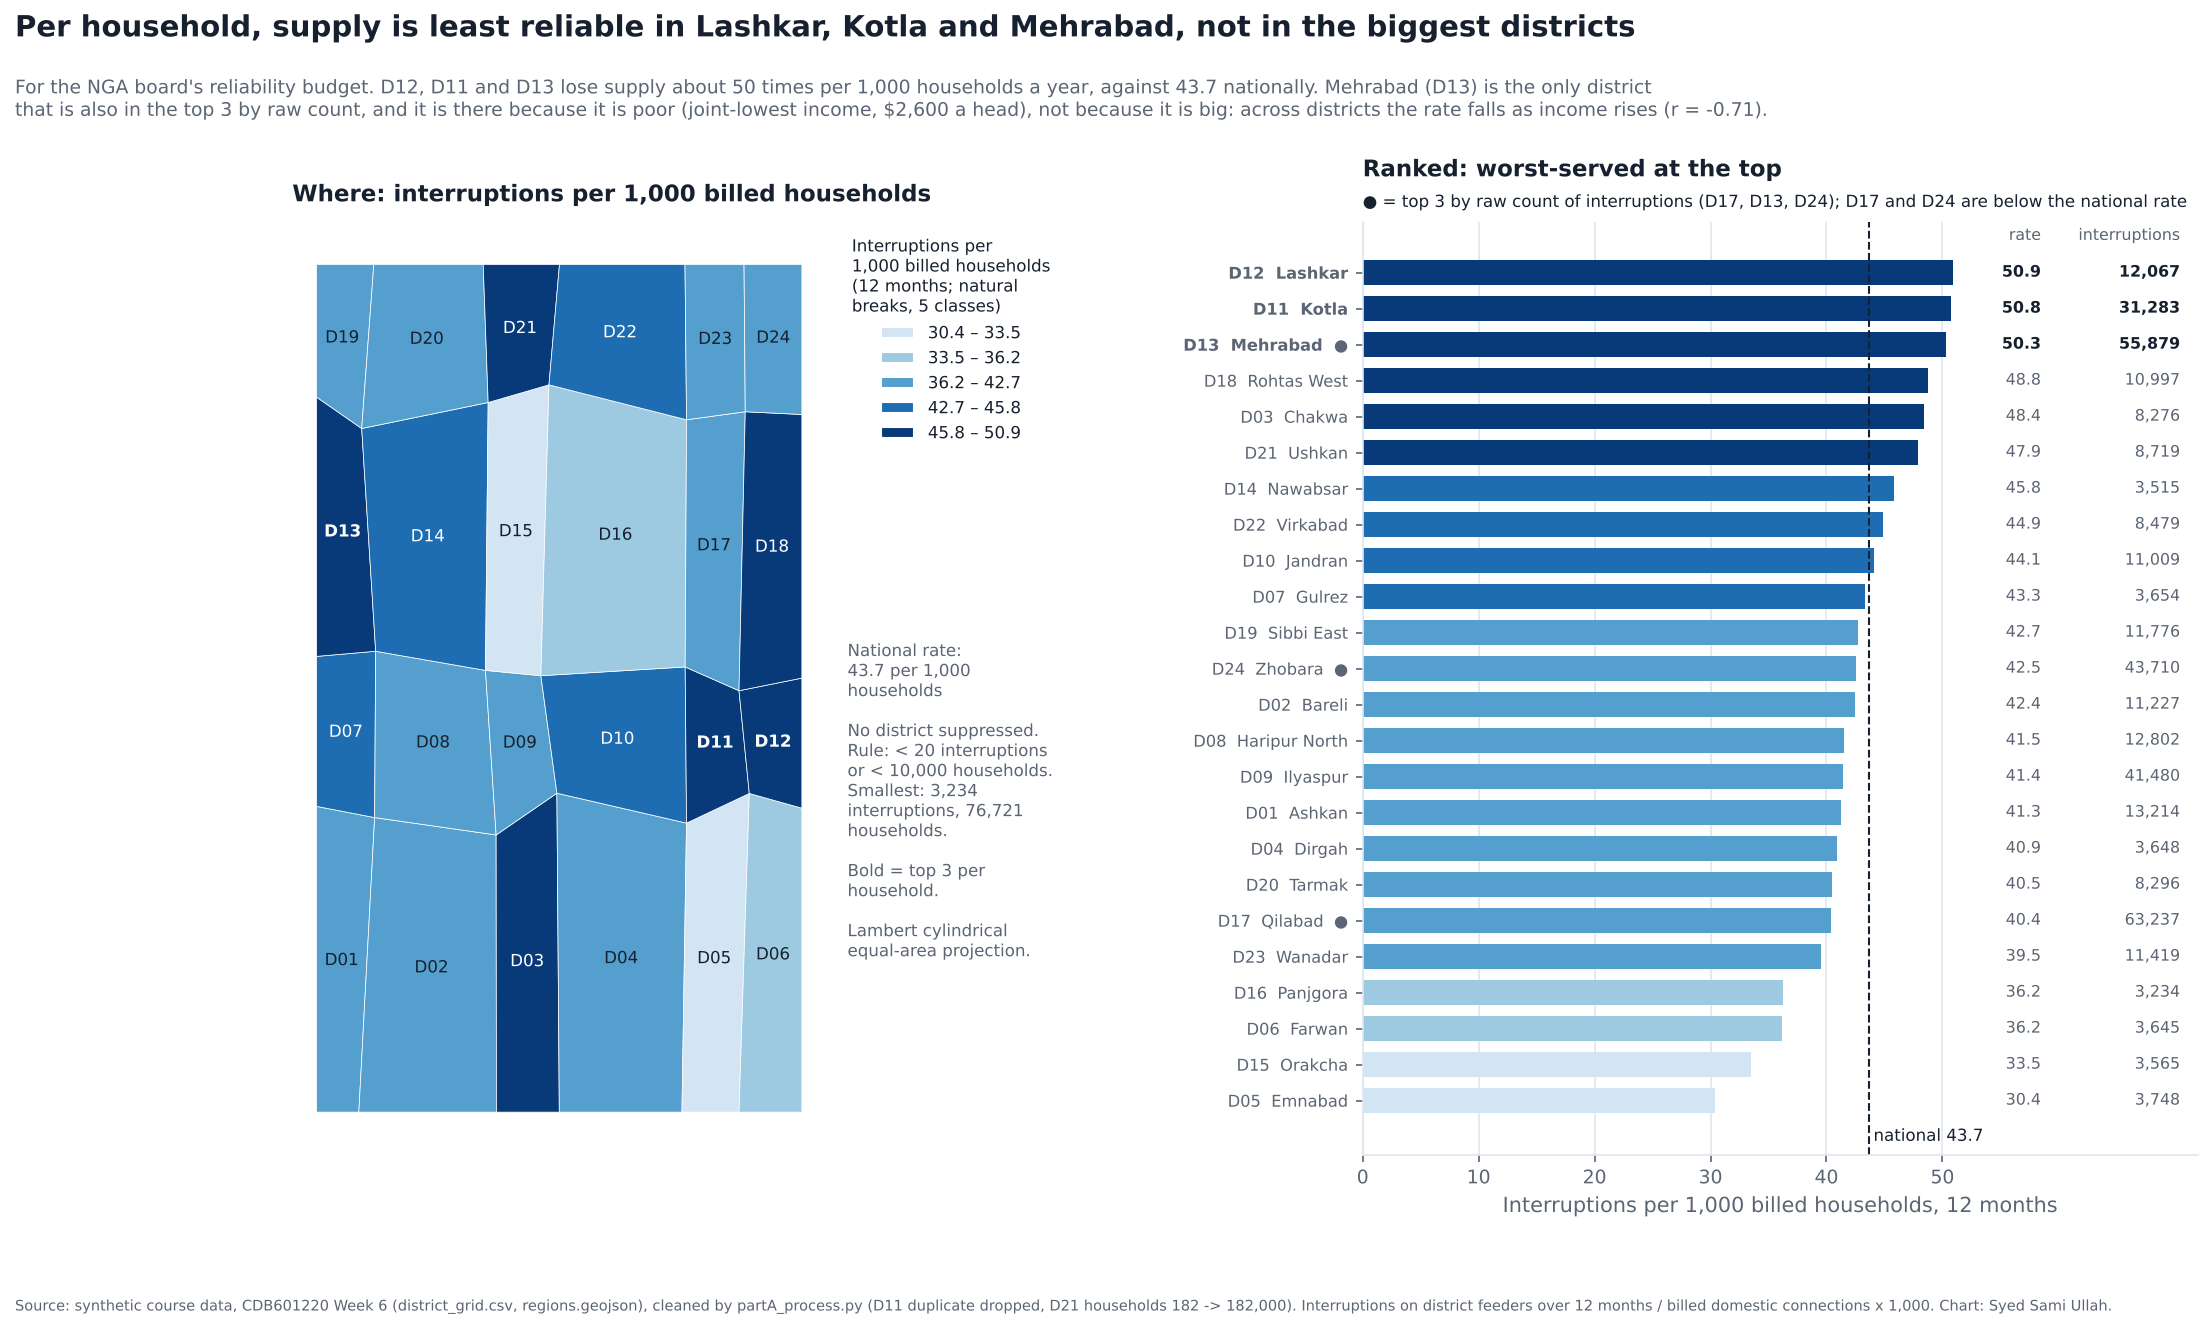

In [5]:
fig = plt.figure(figsize=(15, 8.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.30)
ax, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

gl.choropleth(ax, feats, dict(zip(reg.code, reg.rate)), "natural", 5, cmap=PALETTE["sequential"], fmt="{:.1f}",
              legend_title="Interruptions per\n1,000 billed households\n(12 months; natural\nbreaks, 5 classes)",
              legend_loc="upper left", legend_anchor=(1.02, 1.0))
lat_ts = gl._collection_lat_ts(feats)
cls = dict(zip(reg.code, reg.cls))
for f in feats:
    x, y = gl.equal_area_xy(*gl.representative_point(f["ring"]), lat_ts=lat_ts)
    c = f["code"]
    ax.text(x, y, c, ha="center", va="center", fontsize=8, color="white" if cls[c] >= 3 else INK,
            fontweight="bold" if c in top_rate else "normal")
ax.set_title("Where: interruptions per 1,000 billed households", fontsize=11)
ax.text(1.04, 0.55, f"National rate:\n{pooled:.1f} per 1,000\nhouseholds\n\nNo district suppressed.\nRule: < {MIN_EVENTS} interruptions\n"
        f"or < {MIN_HH:,} households.\nSmallest: {reg.outages.min():,}\ninterruptions, {reg.households.min():,}\nhouseholds.\n\n"
        "Bold = top 3 per\nhousehold.\n\nLambert cylindrical\nequal-area projection.",
        transform=ax.transAxes, fontsize=8, va="top", color=SOFT)

srt = reg.sort_values("rate")
yy = np.arange(len(srt))
axb.barh(yy, srt.rate, color=[SHADE[c] for c in srt.cls], height=0.72)
axb.axvline(pooled, color=INK, lw=1, ls="--")
axb.text(pooled + 0.4, -1.0, f"national {pooled:.1f}", fontsize=8, color=INK, va="center")
for y, (_, rr) in zip(yy, srt.iterrows()):
    axb.text(58.5, y, f"{rr.rate:.1f}", va="center", ha="right", fontsize=7.6,
             color=INK if rr.code in top_rate else SOFT, fontweight="bold" if rr.code in top_rate else "normal")
    axb.text(70.5, y, f"{rr.outages:,}", va="center", ha="right", fontsize=7.6,
             color=INK if rr.code in top_rate else SOFT, fontweight="bold" if rr.code in top_rate else "normal")
axb.set_yticks(yy)
axb.set_yticklabels([f"{c}  {d}" + ("  ●" if c in top_count else "") for c, d in zip(srt.code, srt.district)], fontsize=7.8)
for lab, c in zip(axb.get_yticklabels(), srt.code):
    if c in top_rate:
        lab.set_fontweight("bold")
axb.text(58.5, len(srt) - 0.2, "rate", ha="right", va="bottom", fontsize=7.6, color=SOFT)
axb.text(70.5, len(srt) - 0.2, "interruptions", ha="right", va="bottom", fontsize=7.6, color=SOFT)
axb.set_xlim(0, 72)
axb.set_xticks([0, 10, 20, 30, 40, 50])
axb.set_ylim(-1.5, len(srt) + 0.4)
axb.set_xlabel("Interruptions per 1,000 billed households, 12 months")
axb.grid(axis="y", visible=False)
axb.set_title("Ranked: worst-served at the top", fontsize=11, pad=22)
axb.text(0, 1.012, "● = top 3 by raw count of interruptions (D17, D13, D24); D17 and D24 are below the national rate",
         transform=axb.transAxes, fontsize=8, color=INK, va="bottom")

fig.suptitle("Per household, supply is least reliable in Lashkar, Kotla and Mehrabad, not in the biggest districts",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=0.985)
fig.text(0.01, 0.935,
         f"For the NGA board's reliability budget. D12, D11 and D13 lose supply about 50 times per 1,000 households a year, against {pooled:.1f} nationally. "
         f"Mehrabad (D13) is the only district\nthat is also in the top 3 by raw count, and it is there because it is poor (joint-lowest income, $2,600 a head), "
         f"not because it is big: across districts the rate falls as income rises (r = {r_income:+.2f}).",
         fontsize=9, color=SOFT, va="top")
fig.subplots_adjust(top=0.82, bottom=0.08, left=0.02, right=0.98)
NOTE = ("Source: synthetic course data, CDB601220 Week 6 (district_grid.csv, regions.geojson), cleaned by partA_process.py "
        "(D11 duplicate dropped, D21 households 182 -> 182,000). Interruptions on district feeders over 12 months / billed domestic connections x 1,000. "
        "Chart: Syed Sami Ullah.")
save_fig(fig, HERE / "partC_figure.png", note=NOTE)
if IN_NOTEBOOK:
    fig.savefig(CHARTS / "partC_figure.png", dpi=300, bbox_inches="tight", facecolor=PALETTE["surface"])
show()

**What this chart shows.** The darkest districts on the map and the top of the bars are the same three: Lashkar (D12), Kotla (D11) and Mehrabad (D13), all at 50.3-50.9 interruptions per 1,000 households against 43.7 nationally. The dots show where a raw-count chart would have pointed instead: Qilabad (D17) and Zhobara (D24) have the most interruptions only because they have the most homes, and both are below the national rate.

## 5 · The counterfactual, drawn once for the note

The same map with the raw count instead of the rate. This is **not** for the board; it is here so the note can say exactly what it would have pointed at.

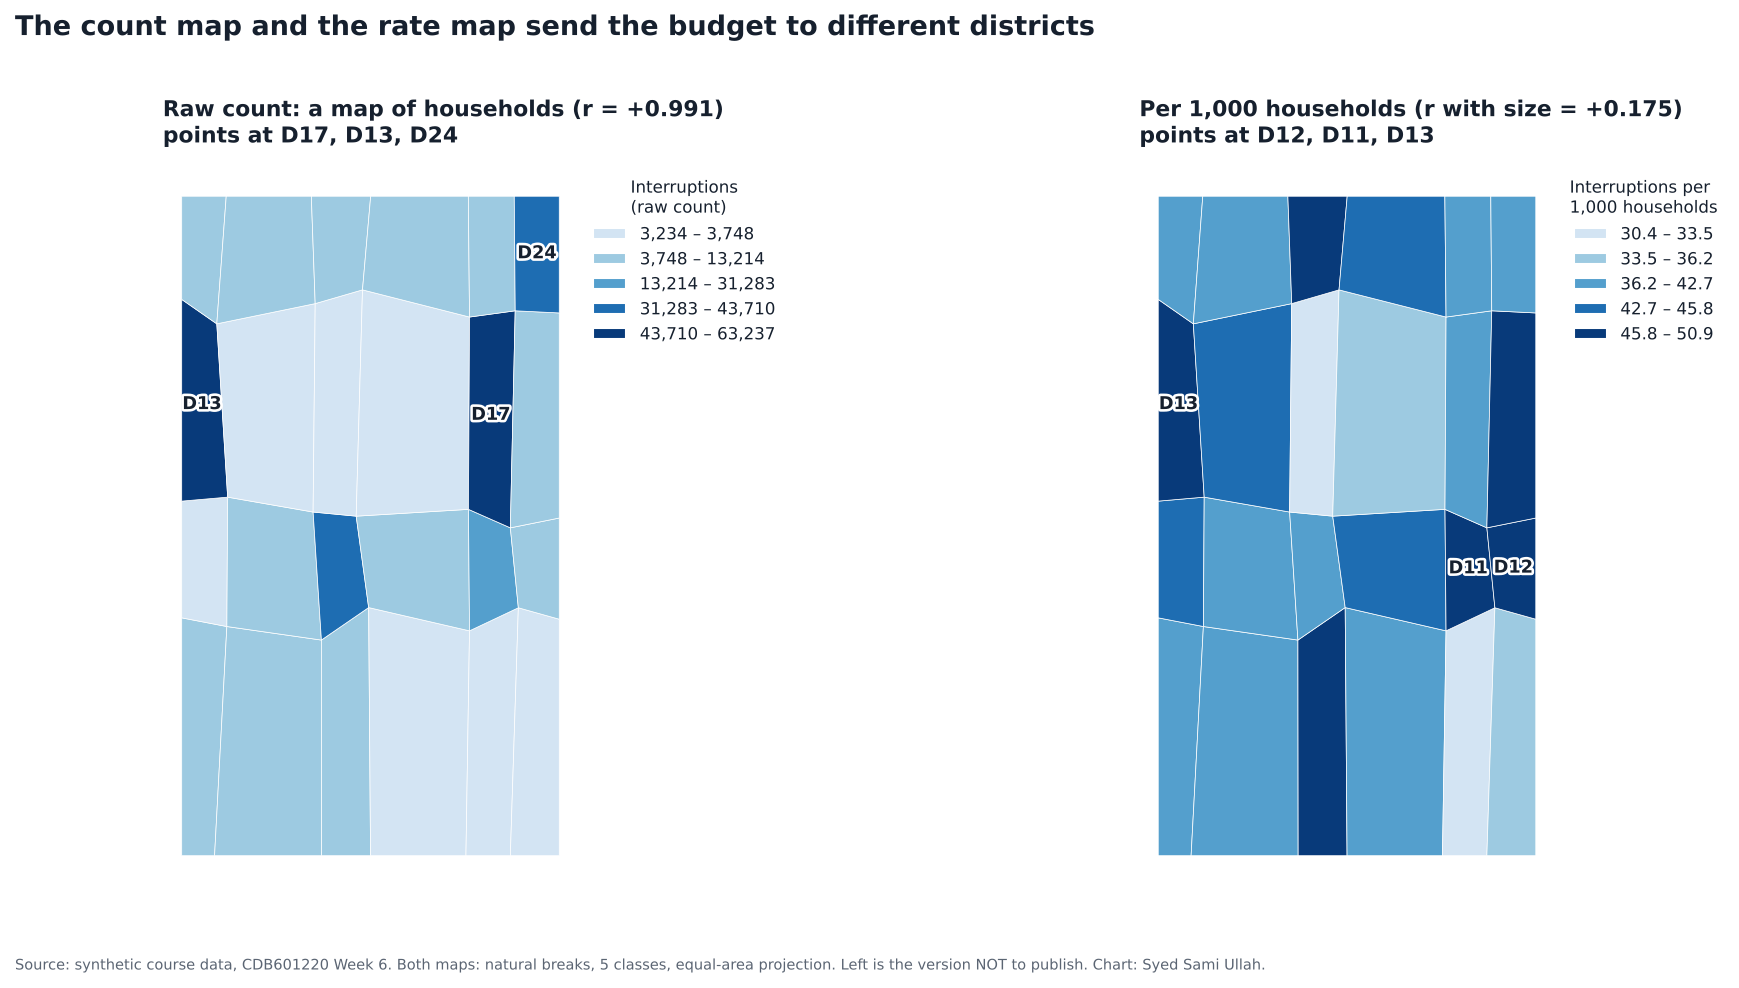

the count version would take the top slots away from:
code district  rate  rank_rate  rank_count
 D11    Kotla  50.8          2           5
 D12  Lashkar  50.9          1           8
and give them to:
code district  rate  rank_rate  rank_count
 D17  Qilabad  40.4         19           1
 D24  Zhobara  42.5         12           3
deutan simulation
  #d3e4f3  ->  #DAE0F3
  #549fcd  ->  #7992CC
  #083a7a  ->  #003779
  #d55e00  ->  #9E8C00


['#DAE0F3', '#7992CC', '#003779', '#9E8C00']

In [6]:
import matplotlib.patheffects as pe
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 6.2))
gl.choropleth(a1, feats, dict(zip(reg.code, reg.outages)), "natural", 5, fmt="{:,.0f}",
              legend_title="Interruptions\n(raw count)", legend_loc="upper left", legend_anchor=(1.0, 1.0))
gl.choropleth(a2, feats, dict(zip(reg.code, reg.rate)), "natural", 5, fmt="{:.1f}",
              legend_title="Interruptions per\n1,000 households", legend_loc="upper left", legend_anchor=(1.0, 1.0))
for a, top in ((a1, top_count), (a2, top_rate)):
    for f in feats:
        if f["code"] in top:
            x, y = gl.equal_area_xy(*gl.representative_point(f["ring"]), lat_ts=lat_ts)
            a.text(x, y, f["code"], ha="center", va="center", fontsize=8.5, color=INK, fontweight="bold",
                   path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
a1.set_title(f"Raw count: a map of households (r = {r_count:+.3f})\npoints at {', '.join(top_count)}", fontsize=10.5)
a2.set_title(f"Per 1,000 households (r with size = {r_rate:+.3f})\npoints at {', '.join(top_rate)}", fontsize=10.5)
fig.suptitle("The count map and the rate map send the budget to different districts", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.subplots_adjust(top=0.82, bottom=0.04, left=0.02, right=0.9, wspace=0.45)
# only kept in charts/ (notebook run): it is evidence for the note, not part of the hand-in
if IN_NOTEBOOK:
    save_fig(fig, CHARTS / "partC_counterfactual.png", note="Source: synthetic course data, CDB601220 Week 6. Both maps: natural breaks, 5 classes, equal-area projection. "
                             "Left is the version NOT to publish. Chart: Syed Sami Ullah.")
show()

lost = reg[reg.code.isin(top_rate) & ~reg.code.isin(top_count)]
gained = reg[reg.code.isin(top_count) & ~reg.code.isin(top_rate)]
print("the count version would take the top slots away from:")
print(lost[["code", "district", "rate", "rank_rate", "rank_count"]].round(1).to_string(index=False))
print("and give them to:")
print(gained[["code", "district", "rate", "rank_rate", "rank_count"]].round(1).to_string(index=False))
from matplotlib.colors import to_hex
vz.cvd_report([to_hex(SHADE[c]) for c in (0, 2, 4)] + [to_hex(ORANGE)], "deutan")

**What the counterfactual shows.** The count map is dark wherever there are many homes (r = +0.991 with households) and lights up Qilabad, Mehrabad and Zhobara. Rank by count, and Lashkar (1st per household, 8th by count) and Kotla (2nd per household, 5th by count) drop out of the top three, while Qilabad, 19th of 24 per household, goes to the top.